<a href="https://colab.research.google.com/github/Sanhith30/ITA0605-ML/blob/main/Lab%20Exercises/Exp06_Naive_Bayes.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Experiment 6: Naive Bayes Classifier (Diabetes Prediction)
**Course:** ITA06 - Machine Learning (Lab)

## Aim
Write a program to implement the Naive Bayes algorithm in Python and to display the results using a confusion matrix and accuracy.

## Background
Naive Bayes applies **Bayes' theorem** `P(C|x) = P(x|C) P(C) / P(x)` with the *naive* assumption that features are conditionally independent given the class: `P(C|x) proportional to P(C) * prod P(x_i|C)`. For continuous features, **Gaussian Naive Bayes** models each `P(x_i|C)` as a normal distribution with a class-specific mean and variance. Prediction picks the class with the highest posterior.



## Setup: Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8, 5)
np.random.seed(42)
print("Libraries imported successfully")

Libraries imported successfully


## Step 1: Data Collection
No download is needed: we generate a realistic **Pima-style diabetes dataset** (768 patients, 8 medical measurements, outcome = diabetic or not). Like the real dataset, some measurements are recorded as `0` when they were not taken (these are really missing values) - a classic preprocessing challenge. The data is saved to `diabetes.csv`.

In [2]:
rng = np.random.RandomState(42)
n = 768
zs = lambda v: (v - v.mean()) / v.std()

age      = np.clip(21 + rng.gamma(2.0, 7.0, n), 21, 81).round()
preg     = np.clip(rng.poisson((age - 18) / 10), 0, 15)
bmi      = np.clip(rng.normal(32, 6.5, n), 18, 60).round(1)
glucose  = np.clip(rng.normal(120, 30, n), 50, 199).round()
bp       = np.clip(rng.normal(70, 12, n), 40, 120).round()
skin     = np.clip(rng.normal(25, 10, n), 5, 60).round()
insulin  = np.clip(rng.lognormal(4.5, 0.7, n), 15, 600).round()
dpf      = np.clip(rng.lognormal(-0.9, 0.55, n), 0.08, 2.4).round(3)

risk = 0.9 * zs(glucose) + 0.6 * zs(bmi) + 0.35 * zs(age) + 0.25 * zs(dpf) + 0.15 * zs(preg)
prob = 1 / (1 + np.exp(-(-0.75 + 1.9 * zs(risk) + rng.normal(0, 0.3, n))))
outcome = rng.binomial(1, prob)

data = pd.DataFrame({"Pregnancies": preg, "Glucose": glucose, "BloodPressure": bp, "SkinThickness": skin,
                     "Insulin": insulin, "BMI": bmi, "DiabetesPedigreeFunction": dpf, "Age": age, "Outcome": outcome})

# Simulate "not measured" entries recorded as 0
for col, frac in {"Glucose": 0.01, "BloodPressure": 0.05, "SkinThickness": 0.30, "Insulin": 0.48, "BMI": 0.01}.items():
    data.loc[rng.rand(n) < frac, col] = 0

data.to_csv("diabetes.csv", index=False)
print("Saved diabetes.csv", data.shape)

Saved diabetes.csv (768, 9)


## Step 2: Data Loading

In [3]:
df = pd.read_csv("diabetes.csv")
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,3,117.0,66.0,0.0,24.0,35.8,0.368,38.0,0
1,1,116.0,66.0,18.0,0.0,29.0,0.427,31.0,0
2,1,132.0,68.0,22.0,115.0,30.1,0.791,31.0,1
3,1,137.0,79.0,28.0,0.0,25.0,0.598,31.0,0
4,7,116.0,0.0,34.0,0.0,20.4,0.493,54.0,0


## Step 3: Data Preprocessing
1. Replace impossible zeros with `NaN`.  2. Split into train and test sets (stratified).  3. Impute missing values with the **median of the training set** (no data leakage).

In [4]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

zero_as_missing = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[zero_as_missing] = df[zero_as_missing].replace(0, np.nan)
print("Missing values after treating zeros as missing:")
print(df.isnull().sum())

X = df.drop(columns="Outcome")
y = df["Outcome"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

imputer = SimpleImputer(strategy="median").fit(X_train)
X_train_imp = pd.DataFrame(imputer.transform(X_train), columns=X.columns)
X_test_imp = pd.DataFrame(imputer.transform(X_test), columns=X.columns)
print("\nTrain:", X_train_imp.shape, "Test:", X_test_imp.shape)

Missing values after treating zeros as missing:
Pregnancies                   0
Glucose                       8
BloodPressure                27
SkinThickness               243
Insulin                     378
BMI                           5
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64

Train: (614, 8) Test: (154, 8)


## Step 4: Exploratory Data Analysis (EDA)

In [5]:
print("Shape:", df.shape)
print(df.describe().T)
print("\nClass balance:\n", df["Outcome"].value_counts(normalize=True).round(3))

Shape: (768, 9)
                          count        mean        std    min        25%  \
Pregnancies               768.0    1.739583   1.600976   0.00    0.75000   
Glucose                   760.0  120.147368  28.917389  50.00  101.00000   
BloodPressure             741.0   69.832659  11.800553  40.00   62.00000   
SkinThickness             525.0   24.980952  10.366362   5.00   18.00000   
Insulin                   390.0  108.233333  86.873749  15.00   51.25000   
BMI                       763.0   32.025688   6.424941  18.00   27.50000   
DiabetesPedigreeFunction  768.0    0.477068   0.288248   0.08    0.27775   
Age                       768.0   35.203125   9.666560  21.00   28.00000   
Outcome                   768.0    0.371094   0.483412   0.00    0.00000   

                              50%       75%    max  
Pregnancies                 1.000    3.0000    9.0  
Glucose                   118.000  140.2500  199.0  
BloodPressure              70.000   78.0000  106.0  
SkinThickne

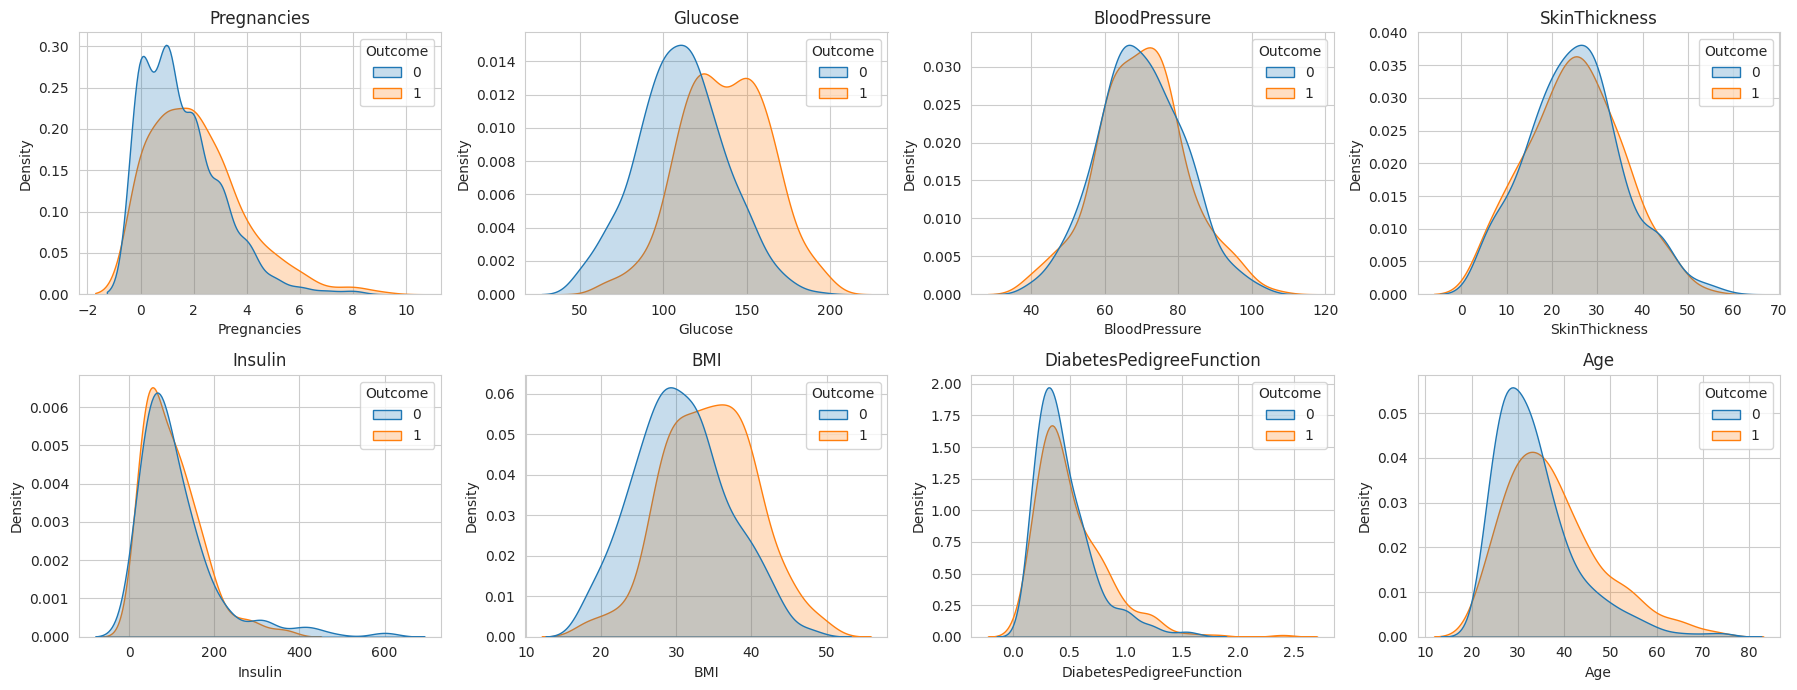

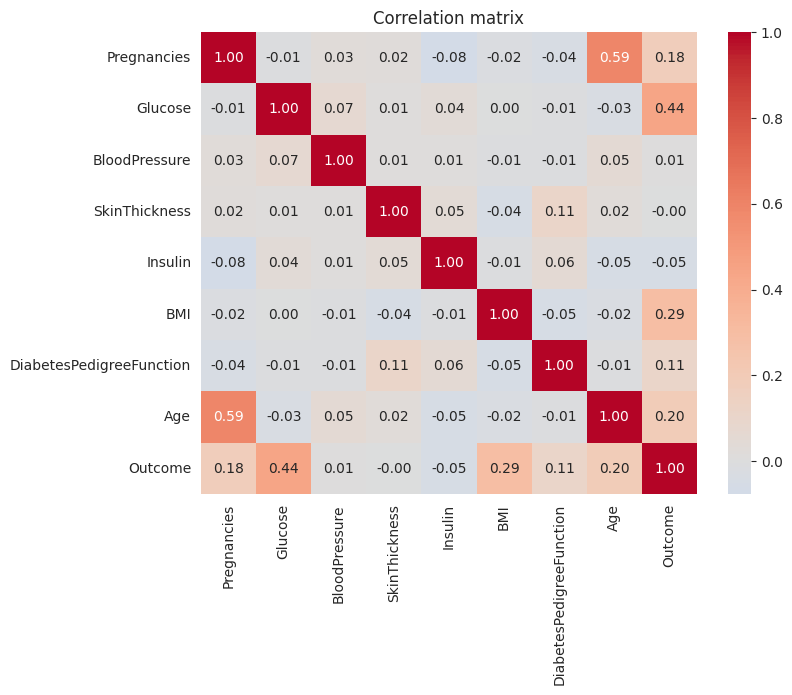

In [6]:
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, col in zip(axes.ravel(), X.columns):
    sns.kdeplot(data=df, x=col, hue="Outcome", fill=True, common_norm=False, ax=ax)
    ax.set_title(col)
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix"); plt.show()

## Step 5: Model Training
We implement **Gaussian Naive Bayes from scratch** to expose the mathematics, and also train scikit-learn's `GaussianNB`.

In [7]:
class GaussianNBScratch:
    def fit(self, X, y, var_smoothing=1e-9):
        X, y = np.asarray(X, dtype=float), np.asarray(y)
        self.classes = np.unique(y)
        self.priors, self.means, self.vars = {}, {}, {}
        eps = var_smoothing * X.var(axis=0).max()
        for c in self.classes:
            Xc = X[y == c]
            self.priors[c] = len(Xc) / len(X)             # P(C)
            self.means[c] = Xc.mean(axis=0)               # per-feature mean
            self.vars[c] = Xc.var(axis=0) + eps           # per-feature variance
        return self

    def _log_posterior(self, X):
        X = np.asarray(X, dtype=float)
        out = []
        for c in self.classes:
            log_lik = -0.5 * np.sum(np.log(2 * np.pi * self.vars[c]) + (X - self.means[c]) ** 2 / self.vars[c], axis=1)
            out.append(np.log(self.priors[c]) + log_lik)  # log P(C) + sum log P(x_i | C)
        return np.column_stack(out)

    def predict_proba(self, X):
        lp = self._log_posterior(X)
        lp -= lp.max(axis=1, keepdims=True)
        p = np.exp(lp)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes[np.argmax(self._log_posterior(X), axis=1)]

scratch = GaussianNBScratch().fit(X_train_imp, y_train)
print("Class priors:", scratch.priors)

from sklearn.naive_bayes import GaussianNB
sk_nb = GaussianNB().fit(X_train_imp, y_train)
print("Models trained.")

Class priors: {np.int64(0): 0.6286644951140065, np.int64(1): 0.3713355048859935}
Models trained.


## Step 6: Model Evaluation
The results are displayed with a **confusion matrix** and **accuracy** (plus precision, recall, F1 and ROC-AUC). We also check that our scratch model agrees with scikit-learn and run 5-fold cross-validation.

Accuracy (sklearn GaussianNB): 0.7597
Accuracy (scratch)           : 0.7597
Same predictions: True
ROC-AUC: 0.7692

               precision    recall  f1-score   support

Non-diabetic       0.79      0.84      0.81        97
    Diabetic       0.69      0.63      0.66        57

    accuracy                           0.76       154
   macro avg       0.74      0.73      0.74       154
weighted avg       0.76      0.76      0.76       154



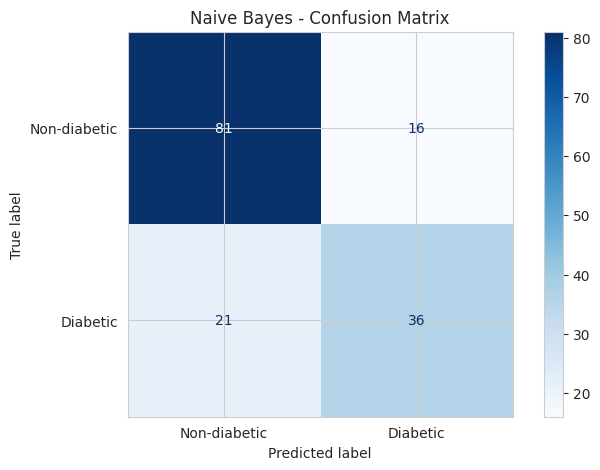

TN=81  FP=16  FN=21  TP=36
5-fold CV accuracy: [0.773 0.708 0.786 0.758 0.693] | mean = 0.743


In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, roc_auc_score, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score

y_pred = sk_nb.predict(X_test_imp)
print("Accuracy (sklearn GaussianNB):", round(accuracy_score(y_test, y_pred), 4))
print("Accuracy (scratch)           :", round(accuracy_score(y_test, scratch.predict(X_test_imp)), 4))
print("Same predictions:", (scratch.predict(X_test_imp) == y_pred).mean() == 1.0)
print("ROC-AUC:", round(roc_auc_score(y_test, sk_nb.predict_proba(X_test_imp)[:, 1]), 4))
print("\n", classification_report(y_test, y_pred, target_names=["Non-diabetic", "Diabetic"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Non-diabetic", "Diabetic"]).plot(cmap="Blues")
plt.title("Naive Bayes - Confusion Matrix"); plt.show()
tn, fp, fn, tp = cm.ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")

X_all = pd.DataFrame(imputer.transform(X), columns=X.columns)
cv = cross_val_score(GaussianNB(), X_all, y, cv=5)
print("5-fold CV accuracy:", cv.round(3), "| mean =", round(cv.mean(), 3))

## Step 7: Prediction on New Data
Predict for a new patient (values in the same order as the columns).

In [9]:
new_patient = pd.DataFrame([[2, 150, 80, 30, 120, 34.5, 0.6, 45]], columns=X.columns)
p = sk_nb.predict_proba(imputer.transform(new_patient))[0]
print(new_patient.T)
print(f"\nP(non-diabetic) = {p[0]:.3f}, P(diabetic) = {p[1]:.3f}")
print("Prediction:", "Diabetic" if p[1] >= 0.5 else "Non-diabetic")

                              0
Pregnancies                 2.0
Glucose                   150.0
BloodPressure              80.0
SkinThickness              30.0
Insulin                   120.0
BMI                        34.5
DiabetesPedigreeFunction    0.6
Age                        45.0

P(non-diabetic) = 0.199, P(diabetic) = 0.801
Prediction: Diabetic


## Conclusion
Gaussian Naive Bayes reached roughly 75-80% accuracy with a ROC-AUC of roughly 0.75-0.8 on this data (exact numbers vary slightly with the split). The from-scratch implementation produced the same predictions as scikit-learn. Naive Bayes is fast, needs little data and gives probabilities, but the independence assumption is violated here (glucose, BMI and age are correlated), which limits accuracy. Handling the disguised missing values (zeros) properly was an important preprocessing step.